# Spam Detection with Logistic Regression

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Classify messages or observations as spam versus non-spam.

**Approach:** Preprocessing, logistic regression and evaluation visualizations.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Regression Logistic  </span>
    </span>
    </center>
<br>


### GUERBOUZ MOHAMMED ALAA EDDINE

### Step 1: Import Necessary Libraries

Before we start working with the dataset, we need to import the necessary Python libraries. These libraries provide tools for data manipulation, visualization, and machine learning.

- **`pandas`**: Used for data manipulation and analysis.
- **`numpy`**: Provides support for numerical operations.
- **`matplotlib.pyplot` and `seaborn`**: Used for data visualization.
- **`train_test_split`**: Splits the dataset into training and testing sets.
- **`StandardScaler`**: Standardizes the features to have a mean of 0 and a standard deviation of 1.
- **`RandomForestClassifier`**: A machine learning model used for classification tasks.
- **`classification_report`, `confusion_matrix`, `accuracy_score`**: Metrics to evaluate the model's performance.

In [23]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

### Step 2: Load the Dataset

We load the dataset from the file `data_spam.csv`. The dataset is separated by semicolons (`;`), and it doesn't have a header row, so we set `header=None`.

- **`file_path`**: Path to the dataset file.
- **`data`**: The dataset is loaded into a pandas DataFrame.
- **`data.head()`**: Displays the first 5 rows of the dataset to get a quick overview of its structure.

In [24]:
# Load the dataset
file_path = 'data_spam.csv'
data = pd.read_csv(file_path, sep=';', header=None)

# Display the first few rows of the dataset
data.head()

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,57
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


### Step 3: Data Preprocessing

Before training the model, we need to preprocess the data to ensure it's in the right format.

1. **Check for Missing Values**:
   - We use `data.isnull().sum()` to check if there are any missing values in the dataset. Missing values can cause issues during model training.

2. **Separate Features and Target Variable**:
   - The features (`X`) are all columns except the last one.
   - The target variable (`y`) is the last column, which indicates whether an email is spam (`1`) or not (`0`).

3. **Split the Dataset**:
   - We split the dataset into training and testing sets using `train_test_split`. The test size is set to 20% of the dataset, and a random seed (`random_state=42`) ensures reproducibility.

4. **Standardize the Features**:
   - We use `StandardScaler` to standardize the features. Standardization ensures that all features have a mean of 0 and a standard deviation of 1, which is important for many machine learning algorithms.

In [25]:
# Check for missing values
data.isnull().sum()

# Check the shape of the dataset
data.shape

# Separate features and target variable
X = data.iloc[:, :-1]  # All columns except the last one
y = data.iloc[:, -1]   # The last column

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Step 4: Model Training

We use the **RandomForestClassifier** to train the model. Random Forest is an ensemble learning method that combines multiple decision trees to improve accuracy and reduce overfitting.

- **`n_estimators=100`**: The number of trees in the forest.
- **`random_state=42`**: Ensures reproducibility of the results.

The model is trained using the training data (`X_train` and `y_train`).

In [27]:
# Initialize the RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

### Step 5: Model Evaluation

After training the model, we evaluate its performance on the test set.

1. **Make Predictions**:
   - We use the trained model to predict the target variable for the test set (`X_test`).

2. **Confusion Matrix**:
   - The confusion matrix shows the number of true positives, true negatives, false positives, and false negatives. It helps us understand how well the model is performing.

3. **Classification Report**:
   - The classification report provides precision, recall, F1-score, and support for each class. These metrics give a detailed view of the model's performance.

4. **Accuracy Score**:
   - The accuracy score is the percentage of correct predictions out of the total predictions.

In [29]:
# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nAccuracy Score:")
print(accuracy_score(y_test, y_pred))

Confusion Matrix:
[[522   9]
 [ 32 358]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       531
           1       0.98      0.92      0.95       390

    accuracy                           0.96       921
   macro avg       0.96      0.95      0.95       921
weighted avg       0.96      0.96      0.96       921


Accuracy Score:
0.9554831704668838


### Step 6: Feature Importance

Random Forest provides a way to measure the importance of each feature in the dataset. Feature importance helps us understand which features contribute the most to the model's predictions.

1. **Get Feature Importances**:
   - We extract the feature importances from the trained model.

2. **Create a DataFrame**:
   - We create a DataFrame to store the feature importances for easier visualization.

3. **Plot Feature Importances**:
   - We use a bar plot to visualize the importance of each feature. This helps us identify the most important features for spam detection.

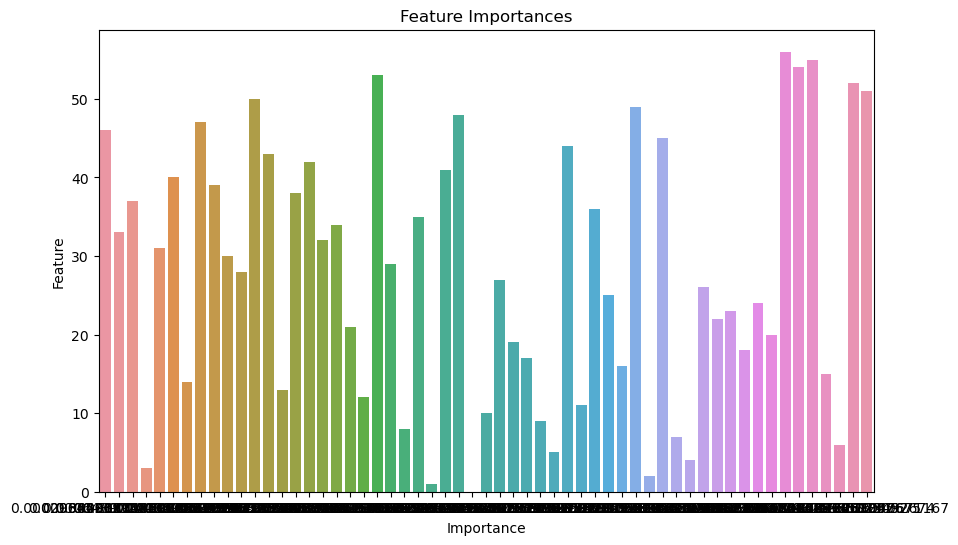

In [30]:
# Get feature importances
importances = model.feature_importances_

# Create a DataFrame for visualization
feature_importances = pd.DataFrame({'feature': range(X.shape[1]), 'importance': importances})
feature_importances = feature_importances.sort_values(by='importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importances)
plt.title('Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

### Step 7: Visualizing the Results

Visualizations help us better understand the model's performance and the dataset.

1. **Confusion Matrix Visualization**:
   - We use a heatmap to visualize the confusion matrix. This makes it easier to interpret the results.

2. **ROC Curve**:
   - The ROC (Receiver Operating Characteristic) curve is a graphical representation of the model's performance. It plots the true positive rate (TPR) against the false positive rate (FPR) at various thresholds.
   - The area under the ROC curve (AUC) is a measure of the model's ability to distinguish between classes. A higher AUC indicates better performance.

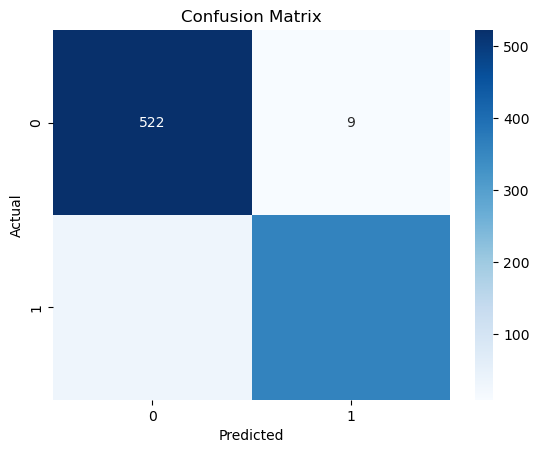

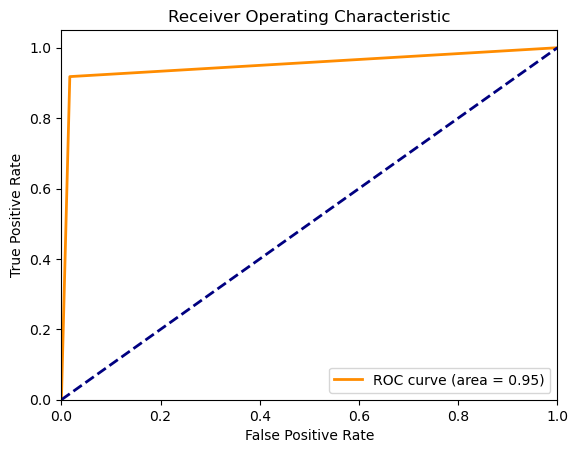

In [31]:
# Confusion Matrix Visualization
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC Curve (if needed)
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

In [32]:
cv_scores = cross_val_score(model, X, y, cv=5)
print(f"Cross-Validation Scores: {cv_scores}")
print(f"Mean CV Accuracy: {np.mean(cv_scores)}")

Cross-Validation Scores: [0.94462541 0.94565217 0.95652174 0.97282609 0.82282609]
Mean CV Accuracy: 0.928490298824529
